# Por que a ponderação por GARCH/GJR diminuiu o retorno da estratégia Momentum, mesmo reduzindo sua volatilidade?

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle

raiz = Path.cwd().resolve()

while not (raiz / "baseDeDados" / "economatica-3.xlsx").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("Repositório não encontrado.")
    raiz = raiz.parent

pasta_funcoes = raiz / "notebooks e resultados" / "momentum com garch"

sys.path.insert(0, str(pasta_funcoes))

from initial_test import (
    preparar_dados,
    prever_vol,
    criar_pesos_vol,
    ewma_vol
)

from funcoes_momentum import (
    criar_top_n,
    criar_pesos,
    backtest)

arquivo_precos = raiz / "baseDeDados" / "economatica-3.xlsx"

arquivo_cache = (
    raiz / "notebooks e resultados"
    / "modelos volatilidade"
    / "cache_vol_modelos.pkl"
)

print("Base encontrada:", arquivo_precos.exists())
print("Cache GARCH/GJR encontrado:", arquivo_cache.exists())
print("Funções importadas com sucesso.")

Base encontrada: True
Cache GARCH/GJR encontrado: True
Funções importadas com sucesso.


In [16]:


# 1. Preparar os dados
precos, retornos, momentos, datas = preparar_dados(
    path=arquivo_precos,
    inicio_hist="2015-01-01",
    inicio_bt="2017-01-01",
    fim="2021-12-31"
)

# 2. Selecionar as cinco ações de maior Momentum
carteira_top5 = criar_top_n(momentos["12-1"], n=5)

# 3. Criar pesos iguais
pesos_iguais = criar_pesos(
    carteira_top5,
    retornos.columns
)

# 4. Recuperar o cache existente
with open(arquivo_cache, "rb") as f:
    cache = pickle.load(f)

# Verificar se o cache corresponde aos dados atuais
assinatura = (
    tuple(retornos.columns),
    str(retornos.index[0]),
    str(retornos.index[-1]),
    len(datas),
    str(datas[0]),
    str(datas[-1]),
    21,
    252
)

if cache.get("fingerprint") != assinatura:
    raise ValueError("O cache não corresponde aos dados atuais.")

# 5. Recuperar as previsões GJR(756)
sigma_gjr = cache["specs"][("gjr", 756)][0]

# 6. Reconstruir os pesos GJR
pesos_gjr = criar_pesos_vol(
    carteira_top5,
    sigma_gjr,
    retornos.columns
)

print("Número de rebalanceamentos:", len(carteira_top5))

print("\nPesos iguais:")
display(pesos_iguais.head())

print("\nPesos GJR:")
display(pesos_gjr.head())

[dados] 30 ativos | 2015-01-02 a 2021-12-30 | 60 datas de sinal
Número de rebalanceamentos: 60

Pesos iguais:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-02-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0
2017-03-31,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.2,0.2,0.0
2017-04-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.2,0.0,0.0,0.0,0.2,0.0,0.0
2017-05-31,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0



Pesos GJR:


,ABEV3,B3SA3,BBDC4,BBAS3,BRKM5,CAML3,CMIG4,CYRE3,EMBJ3,EGIE3,...,PETR4,PRIO3,RADL3,SANB3,SANB11,CSNA3,TAEE11,USIM5,VALE3,WEGE3
2017-01-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.279491,0.000000,0.0,0.000000,0.0,0.0,0.0,0.179511,0.000000,0.0
2017-02-24,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.285598,0.000000,0.0,0.000000,0.0,0.0,0.0,0.188150,0.000000,0.0
2017-03-31,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.237848,0.0,0.0,0.0,0.189646,0.215847,0.0
2017-04-28,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.164409,0.0,0.250472,0.0,0.0,0.0,0.209038,0.000000,0.0
2017-05-31,0.0,0.0,0.0,0.278667,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.177218,0.0,0.000000,0.0,0.0,0.0,0.201595,0.000000,0.0


In [17]:
linhas = []

for data, linha in carteira_top5.iterrows():

    for ranking, ativo in enumerate(linha.dropna(), start=1):

        peso_igual = pesos_iguais.loc[data, ativo]
        peso_gjr = pesos_gjr.loc[data, ativo]

        linhas.append({
            "Data": data,
            "Ativo": ativo,
            "Ranking Momentum": ranking,
            "Momentum (%)": momentos["12-1"].loc[data, ativo] * 100,
            "Peso igual (%)": peso_igual * 100,
            "Peso GJR (%)": peso_gjr * 100,
            "Diferença (p.p.)": (peso_gjr - peso_igual) * 100
        })

tabela_pesos = pd.DataFrame(linhas)

display(tabela_pesos.head(15).round(2))

,Data,Ativo,Ranking Momentum,Momentum (%),Peso igual (%),Peso GJR (%),Diferença (p.p.)
0,2017-01-31,MGLU3,1,726.23,20.0,10.92,-9.08
1,2017-01-31,GOAU4,2,389.70,20.0,19.77,-0.23
2,2017-01-31,USIM5,3,384.88,20.0,17.95,-2.05
3,2017-01-31,PETR4,4,223.26,20.0,27.95,7.95
4,2017-01-31,GGBR4,5,218.17,20.0,23.41,3.41
5,2017-02-24,MGLU3,1,581.20,20.0,11.50,-8.50
6,2017-02-24,USIM5,2,457.17,20.0,18.82,-1.18
7,2017-02-24,GOAU4,3,391.83,20.0,19.31,-0.69
8,2017-02-24,GGBR4,4,249.51,20.0,21.81,1.81
9,2017-02-24,PETR4,5,223.11,20.0,28.56,8.56


,Peso_GJR_medio,Diferenca_media,N_observacoes
Ranking Momentum,,,
1,15.516,-4.484,60
2,17.252,-2.748,60
3,20.657,0.657,60
4,22.069,2.069,60
5,24.507,4.507,60


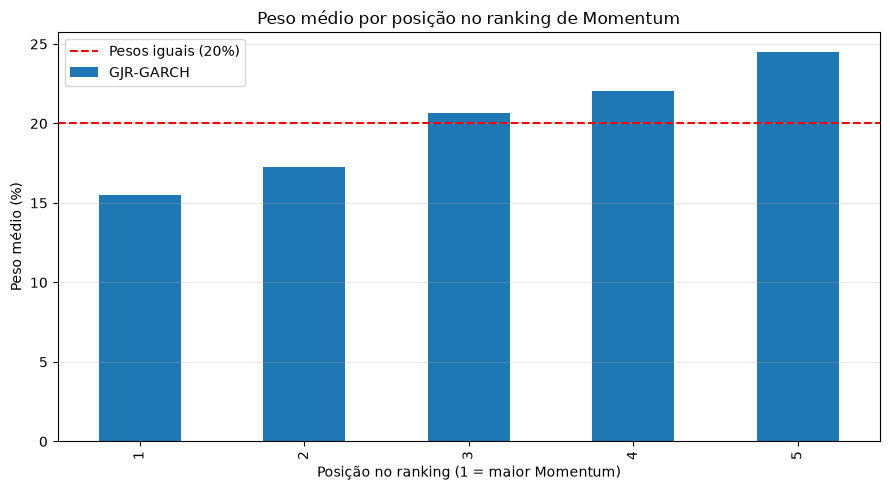

In [18]:
# Agrupar as observações pelo ranking de Momentum
resumo_ranking = (
    tabela_pesos
    .groupby("Ranking Momentum")
    .agg(
        Peso_GJR_medio=("Peso GJR (%)", "mean"),
        Diferenca_media=("Diferença (p.p.)", "mean"),
        N_observacoes=("Ativo", "count")
    )
)

display(resumo_ranking.round(3))

# Gráfico comparando os pesos
ax = resumo_ranking["Peso_GJR_medio"].plot(
    kind="bar",
    figsize=(9, 5),
    label="GJR-GARCH"
)

ax.axhline(
    y=20,
    linestyle="--",
    color="red",
    label="Pesos iguais (20%)"
)

ax.set_title("Peso médio por posição no ranking de Momentum")
ax.set_xlabel("Posição no ranking (1 = maior Momentum)")
ax.set_ylabel("Peso médio (%)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
linhas_retornos = []

datas_sinais = carteira_top5.index

for i in range(len(datas_sinais) - 1):

    data = datas_sinais[i]
    proxima_data = datas_sinais[i + 1]

    # Posições dos sinais no calendário de pregões
    pos_atual = retornos.index.get_loc(data)
    pos_proxima = retornos.index.get_loc(proxima_data)

    # Entrada no fechamento do pregão seguinte ao sinal
    # Retornos começam no segundo pregão após o sinal
    inicio = pos_atual + 2

    # Último retorno antes da próxima carteira entrar
    fim = pos_proxima + 1

    for ranking, ativo in enumerate(
        carteira_top5.loc[data].dropna(), start=1
    ):

        r = retornos[ativo].iloc[inicio:fim + 1]

        retorno_futuro = (
            (1 + r).prod() - 1
            if r.notna().all() and not r.empty
            else np.nan
        )

        linhas_retornos.append({
            "Data": data,
            "Ativo": ativo,
            "Ranking Momentum": ranking,
            "Retorno futuro (%)": retorno_futuro * 100,
            "Peso GJR (%)": pesos_gjr.loc[data, ativo] * 100
        })

tabela_retornos = pd.DataFrame(linhas_retornos)

resumo_retornos = (
    tabela_retornos
    .groupby("Ranking Momentum")
    .agg(
        Retorno_medio=("Retorno futuro (%)", "mean"),
        Peso_GJR_medio=("Peso GJR (%)", "mean"),
        N_observacoes=("Retorno futuro (%)", "count")
    )
)

display(resumo_retornos.round(3))

,Retorno_medio,Peso_GJR_medio,N_observacoes
Ranking Momentum,,,
1,5.289,15.492,59
2,2.953,17.214,59
3,3.251,20.741,59
4,2.866,22.053,59
5,3.882,24.500,59


In [20]:
# Criar uma cópia da tabela anterior
atribuicao = tabela_retornos.copy()

# Diferença entre o peso GJR e o peso igual
atribuicao["Delta peso (p.p.)"] = (
    atribuicao["Peso GJR (%)"] - 20
)

# Contribuição diferencial aproximada, em pontos percentuais
atribuicao["Contribuição (p.p.)"] = (
    atribuicao["Delta peso (p.p.)"]
    * atribuicao["Retorno futuro (%)"] / 100
)

# Resumir por ranking de Momentum
resumo_atribuicao = (
    atribuicao
    .groupby("Ranking Momentum")
    .agg(
        Retorno_medio=("Retorno futuro (%)", "mean"),
        Delta_peso_medio=("Delta peso (p.p.)", "mean"),
        Contribuicao_media=("Contribuição (p.p.)", "mean")
    )
)

display(resumo_atribuicao.round(3))

# Somar as contribuições das cinco posições
print(
    "\nDiferença mensal média aproximada GJR - pesos iguais:",
    round(resumo_atribuicao["Contribuicao_media"].sum(), 3),
    "p.p."
)

,Retorno_medio,Delta_peso_medio,Contribuicao_media
Ranking Momentum,,,
1,5.289,-4.508,-0.236
2,2.953,-2.786,-0.098
3,3.251,0.741,-0.109
4,2.866,2.053,-0.133
5,3.882,4.500,-0.056



Diferença mensal média aproximada GJR - pesos iguais: -0.633 p.p.


In [21]:
linhas_decomposicao = []

for ranking, grupo in atribuicao.groupby("Ranking Momentum"):

    dw = grupo["Delta peso (p.p.)"]
    r = grupo["Retorno futuro (%)"]

    # Efeito dos pesos médios
    efeito_medio = dw.mean() * r.mean() / 100

    # Efeito da covariância
    efeito_cov = (
        (dw - dw.mean()) *
        (r - r.mean())
    ).mean() / 100

    linhas_decomposicao.append({
        "Ranking": ranking,
        "Efeito peso médio (p.p.)": efeito_medio,
        "Efeito covariância (p.p.)": efeito_cov,
        "Contribuição total (p.p.)": efeito_medio + efeito_cov
    })

decomposicao = pd.DataFrame(linhas_decomposicao).set_index("Ranking")

display(decomposicao.round(3))

print("\nTotal:")
display(decomposicao.sum().round(3))

,Efeito peso médio (p.p.),Efeito covariância (p.p.),Contribuição total (p.p.)
Ranking,,,
1,-0.238,0.002,-0.236
2,-0.082,-0.016,-0.098
3,0.024,-0.133,-0.109
4,0.059,-0.192,-0.133
5,0.175,-0.231,-0.056



Total:


Efeito peso médio (p.p.)    -0.063
Efeito covariância (p.p.)   -0.569
Contribuição total (p.p.)   -0.633
dtype: float64

In [23]:
periodos = {
    "Treinamento (2017–2020)": ("2017-01-01", "2020-12-31"),
    "Validação (2021)": ("2021-01-01", "2021-12-31")
}




linhas_periodos = []

for periodo, (inicio, fim) in periodos.items():

    amostra = atribuicao[
        atribuicao["Data"].between(inicio, fim)
    ].dropna(subset=["Retorno futuro (%)"])

    for ranking, grupo in amostra.groupby("Ranking Momentum"):

        dw = grupo["Delta peso (p.p.)"]
        r = grupo["Retorno futuro (%)"]

        efeito_medio = dw.mean() * r.mean() / 100

        efeito_cov = (
            (dw - dw.mean()) * (r - r.mean())
        ).mean() / 100

        linhas_periodos.append({
            "Período": periodo,
            "Ranking": ranking,
            "Efeito médio": efeito_medio,
            "Efeito covariância": efeito_cov,
            "Contribuição total": efeito_medio + efeito_cov
        })

decomposicao_periodos = pd.DataFrame(linhas_periodos)

for periodo, tabela in decomposicao_periodos.groupby("Período"):

    print(f"\n{periodo}")

    display(
        tabela.drop(columns="Período")
        .set_index("Ranking")
        .round(3)
    )

    print("\nTotal do período:")
    display(
        tabela[
            ["Efeito médio", "Efeito covariância", "Contribuição total"]
        ].sum().round(3)
    )


Treinamento (2017–2020)


,Efeito médio,Efeito covariância,Contribuição total
Ranking,,,
1,-0.355,0.102,-0.253
2,-0.121,0.003,-0.119
3,0.029,-0.164,-0.134
4,0.073,-0.262,-0.189
5,0.130,-0.164,-0.034



Total do período:


Efeito médio         -0.244
Efeito covariância   -0.485
Contribuição total   -0.729
dtype: float64


Validação (2021)


,Efeito médio,Efeito covariância,Contribuição total
Ranking,,,
1,0.021,-0.184,-0.163
2,0.027,-0.036,-0.008
3,-0.018,0.020,0.002
4,-0.044,0.154,0.109
5,0.076,-0.228,-0.152



Total do período:


Efeito médio          0.062
Efeito covariância   -0.274
Contribuição total   -0.212
dtype: float64

In [24]:
from funcoes_momentum import aplicar_custos

# Refazer os backtests com as mesmas datas
resultado_igual = backtest(
    pesos_iguais, retornos,
    inicio="2017-01-01",
    fim="2021-12-31"
)

resultado_gjr = backtest(
    pesos_gjr, retornos,
    inicio="2017-01-01",
    fim="2021-12-31"
)

# Diferenças diárias entre as estratégias
diferencas = pd.DataFrame({
    "Bruta": (
        resultado_gjr["Retorno"]
        - resultado_igual["Retorno"]
    ),
    "Liquida": (
        aplicar_custos(resultado_gjr, 0.001)
        - aplicar_custos(resultado_igual, 0.001)
    )
})

# Separar pelas datas reais dos retornos
linhas = []

for periodo, (inicio, fim) in periodos.items():

    amostra = diferencas.loc[inicio:fim]

    bruta = amostra["Bruta"].mean() * 252 * 100
    liquida = amostra["Liquida"].mean() * 252 * 100

    linhas.append({
        "Período": periodo,
        "Diferença bruta anualizada (p.p.)": bruta,
        "Diferença líquida anualizada (p.p.)": liquida,
        "Efeito adicional dos custos (p.p.)": liquida - bruta
    })

comparacao_efetiva = pd.DataFrame(linhas)

display(comparacao_efetiva.round(3))

,Período,Diferença bruta anualizada (p.p.),Diferença líquida anualizada (p.p.),Efeito adicional dos custos (p.p.)
0,Treinamento (2017–2020),-8.286,-8.394,-0.108
1,Validação (2021),-2.030,-2.112,-0.082
